# Full run: HR-ETE-GNN, α = 0.9 (sensitivity)

One Rényi order, the full 2006–2024 walk-forward, **10 seeds**, in **deterministic mode**. The result is compared with H-ETE-GNN (Shannon, α = 1) from `run_alpha_1.0.ipynb`. The notebooks can run in any order. If the baseline isn't finished yet, this one still trains, and section 3.2 says to come back. Re-running all cells later skips the training and only does the comparison.

**Role in the thesis: sensitivity analysis, not the confirmatory test.** α\* = 0.7 was frozen on the validation span (`run_full.ipynb` stage 1) and only α\* carries the hypothesis test (manuscript §3.5). This α goes in the appendix sensitivity table. Its p-values below are descriptive. Read across several α they are a multiple-comparison family; `compare_all_alphas.ipynb` adjusts for that.

α = 0.9 was in the selection grid. Its 3-seed validation runs are in `../runs/val/`.

**Same experiment for every α.** Configuration, data panel, estimator, architecture, training, Hurst regime calendar, seeds and surrogate permutations all come unchanged from `../hrete_full.py`. The only thing that differs between the α notebooks is α. Checkpoints go to `../runs/full/`.

**Reproducible.** `hrete_full.py` switches on PyTorch's deterministic mode, so the same α and seed give bit-identical forecasts every time. Each saved run records that it was made this way, and the results sections refuse to use a run that wasn't.

**Safe to interrupt.** Each (α, seed) run is saved to its own file once it finishes. If the kernel dies or you stop it, restart the kernel and run all cells again. Finished seeds are skipped. Seeds that were in flight are redone and come out identical to an uninterrupted run.

**Expected time:** about 20 minutes on the RTX 2070. Each run took about 8.6 min with 6 running at once, so 10 seeds take two waves. Run the notebooks **one at a time**: two at once share the GPU and both slow down.

## 0. Settings

In [1]:
ALPHA = 0.9

import os, sys, time
from pathlib import Path
HERE = Path.cwd()
if not (HERE / "alpha_common.py").exists():        # launched from final_results/ or the repo root
    for cand in (HERE / "alpha_runs", HERE / "final_results" / "alpha_runs"):
        if (cand / "alpha_common.py").exists():
            HERE = cand
            break
sys.path.insert(0, str(HERE))

import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import torch
import alpha_common as ac
hf = ac.hf

# Smoke mode: tiny budgets, separate folders, numbers mean nothing.  Only for
# checking the notebook runs end to end.  Set RUN_ALPHA_SMOKE=1 to enable.
SMOKE = os.environ.get("RUN_ALPHA_SMOKE") == "1"
SEEDS, RUNS_ROOT, N_JOBS, OVERRIDES = hf.SEEDS, hf.RUNS_DIR, ac.N_JOBS, {}
TABLES_ROOT = HERE / "tables"
if SMOKE:
    SEEDS, RUNS_ROOT, N_JOBS = (0, 1), HERE / "runs_smoke", 2
    TABLES_ROOT = HERE / "tables_smoke"
    OVERRIDES = dict(epochs=2, finetune_epochs=1, n_shuffles=5)

TABLES = TABLES_ROOT / f"alpha{ALPHA:g}"
TABLES.mkdir(parents=True, exist_ok=True)
ac.check_device()                       # stops if CUDA is missing: every alpha runs on cuda
RUN_OVERRIDES = ac.run_overrides(**OVERRIDES)
print(f"torch {torch.__version__}   cuda: {torch.cuda.get_device_name(0)}")
print(f"alpha={ALPHA:g}   model={hf.arm_label(ALPHA)}   seeds={SEEDS}   SMOKE={SMOKE}")
print(f"device={RUN_OVERRIDES['device']}   n_jobs={N_JOBS}   deterministic={hf.DETERMINISTIC}")
print(f"checkpoints -> {RUNS_ROOT / 'full'}")
print(f"tables      -> {TABLES}")

torch 2.14.1+cu126   cuda: NVIDIA GeForce RTX 2070
alpha=0.9   model=HR-ETE-GNN(a=0.9)   seeds=(0, 1, 2, 3, 4, 5, 6, 7, 8, 9)   SMOKE=False
device=cuda   n_jobs=6   deterministic=True
checkpoints -> C:\Users\ramoy\repositories\HR-ETE-GNN-Thesis\HR-ETE-GNN-Thesis\final_results\runs\full
tables      -> C:\Users\ramoy\repositories\HR-ETE-GNN-Thesis\HR-ETE-GNN-Thesis\final_results\alpha_runs\tables\alpha0.9


## 1. Pre-flight checks

Confirms the frozen data panel, and shows which seeds of this α (and of the baseline) are already on disk. `deterministic` counts the saved seeds that were made in deterministic mode. It should always equal `seeds_done`.

In [2]:
data = hf.prepare_data(hf.make_config())           # frozen panel, never re-downloaded here
cfg = hf.make_config(**RUN_OVERRIDES)
changes = pd.DatetimeIndex(data["changes"])
print(f"data panel sha256 {ac.panel_sha256()[:16]}...   {data['prices'].shape[0]} days x {data['prices'].shape[1]} ETFs")
print(f"edge builder key  {hf.edge_kind(ALPHA)}   validation end {hf.VAL_END}   alpha* = {ac.ALPHA_STAR:g}")
display(ac.status(sorted({1.0, ALPHA}), SEEDS, RUNS_ROOT))

data panel sha256 d57aeab57235282c...   5363 days x 10 ETFs
edge builder key  RETE0.9   validation end 2009-12-31   alpha* = 0.7


,model,seeds_done,of,complete,deterministic,missing
alpha,,,,,,
0.9,HR-ETE-GNN(a=0.9),0,10,False,0,"[0, 1, 2, 3, 4, 5, 6, 7, 8, 9]"
1.0,H-ETE-GNN,10,10,True,10,[]


## 2. Run α = 0.9, all seeds

In [3]:
todo = ac.specs(ALPHA, SEEDS, RUNS_ROOT)
if SMOKE and ALPHA != 1.0:                          # smoke mode: make a tiny baseline too
    todo = ac.specs(1.0, SEEDS, RUNS_ROOT) + todo
t0 = time.time()
_ = hf.run_many(todo, n_jobs=N_JOBS, cfg_overrides=RUN_OVERRIDES)
print(f"wall clock this session: {(time.time() - t0) / 60:.1f} min")
display(ac.status(sorted({1.0, ALPHA}), SEEDS, RUNS_ROOT))

0 of 10 runs already done; 10 to go with n_jobs=6
[  1/10] full alpha=0.9  seed=3    9.1 min  refits=42  elapsed  0.16 h  ETA  1.40 h
[  2/10] full alpha=0.9  seed=5    9.2 min  refits=42  elapsed  0.16 h  ETA  0.62 h
[  3/10] full alpha=0.9  seed=1    9.2 min  refits=42  elapsed  0.16 h  ETA  0.36 h
[  4/10] full alpha=0.9  seed=2    9.3 min  refits=42  elapsed  0.16 h  ETA  0.24 h
[  5/10] full alpha=0.9  seed=4    9.3 min  refits=42  elapsed  0.16 h  ETA  0.16 h
[  6/10] full alpha=0.9  seed=0    9.3 min  refits=42  elapsed  0.16 h  ETA  0.10 h
[  7/10] full alpha=0.9  seed=6    8.0 min  refits=42  elapsed  0.29 h  ETA  0.12 h
[  8/10] full alpha=0.9  seed=7    8.1 min  refits=42  elapsed  0.29 h  ETA  0.07 h
[  9/10] full alpha=0.9  seed=8    8.1 min  refits=42  elapsed  0.29 h  ETA  0.03 h
[ 10/10] full alpha=0.9  seed=9    8.0 min  refits=42  elapsed  0.29 h  ETA  0.00 h
wall clock this session: 17.5 min


,model,seeds_done,of,complete,deterministic,missing
alpha,,,,,,
0.9,HR-ETE-GNN(a=0.9),10,10,True,10,[]
1.0,H-ETE-GNN,10,10,True,10,[]


## 3. Results

### 3.1 Paper metrics over 2006–2024

Mean ± SD over the seeds, laid out like the paper's Table 6.

In [4]:
new_runs = ac.load(ALPHA, SEEDS, RUNS_ROOT)
BASE_READY = bool(ac.status((1.0,), SEEDS, RUNS_ROOT).loc[1.0, "complete"])
base_runs = ac.load(1.0, SEEDS, RUNS_ROOT) if BASE_READY else None
by_alpha = {ALPHA: new_runs} if (ALPHA == 1.0 or not BASE_READY) else {1.0: base_runs, ALPHA: new_runs}
per_seed = ac.per_seed_metrics(by_alpha)
per_seed.to_csv(TABLES / "full_span_per_seed.csv", index=False)
fmt = ac.paper_table(per_seed)
fmt.to_csv(TABLES / "full_span_paper_metrics.csv")
display(fmt)
if not BASE_READY:
    print("Shannon baseline not finished yet: run run_alpha_1.0.ipynb, then re-run this notebook "
          "(training is skipped) to add the baseline row and section 3.2.")

,RMSE,MAE,MAPE,Correlation,HitRatio,QLIKE
Model,,,,,,
H-ETE-GNN,0.6088 ± 0.1711,0.2372 ± 0.0243,13.2048 ± 0.7045,0.8655 ± 0.0221,0.5532 ± 0.0024,0.1347 ± 0.1602
HR-ETE-GNN(a=0.9),0.6479 ± 0.1746,0.2758 ± 0.0170,15.9717 ± 0.5166,0.8327 ± 0.0388,0.5415 ± 0.0018,5.5043 ± 5.9729
"Lee & Cho (2025), H-ETE-GNN",0.1623,0.1024,6.6555,0.9605,0.7206,-


### 3.2 Test span (after `VAL_END`) against Shannon

The same tests as section 6.2 of `run_full.ipynb`. Each arm's forecast is the seed-mean. d = QLIKE(H-ETE-GNN) − QLIKE(this α), so d > 0 means Rényi is better.

test span 2010-01-04 -> 2024-05-29  (3625 days)


,value
quantity,
"QLIKE, H-ETE-GNN",0.03465
"QLIKE, HR-ETE-GNN(a=0.9)",0.05893
"QLIKE improvement, %",-70.05400
GW unconditional: Wald stat,130.54004
GW unconditional: p (two-sided),0.00000
GW unconditional: p (one-sided),1.00000
DM (HLN) on QLIKE: stat,-29.82531
DM (HLN) on QLIKE: p one-sided,1.00000
"MSE improvement, %",-28.66047


,ETF,QLIKE_base,QLIKE_new,improvement_pct,DM_stat,p,bh_threshold,p_adj,reject
0,EWA,0.0237,0.0373,-57.4967,-9.9054,1.0000,0.05,1.0,False
1,EWC,0.0241,0.0916,-279.5873,-30.5599,1.0000,0.06,1.0,False
2,EWG,0.0509,0.0549,-7.9496,-2.1096,0.9825,0.02,1.0,False
3,EWJ,0.0213,0.0272,-27.7438,-11.1653,1.0000,0.07,1.0,False
4,EWT,0.0261,0.0535,-104.6137,-18.8581,1.0000,0.08,1.0,False
5,EWU,0.0321,0.0495,-54.0563,-5.9657,1.0000,0.03,1.0,False
6,EWW,0.0231,0.0270,-16.8836,-6.0989,1.0000,0.04,1.0,False
7,EWY,0.0174,0.0388,-123.0024,-17.8362,1.0000,0.09,1.0,False
8,EWZ,0.1006,0.1047,-4.0593,-1.3492,0.9113,0.01,1.0,False
9,EZA,0.0272,0.1048,-285.8513,-16.3586,1.0000,0.10,1.0,False


HR-ETE-GNN(a=0.9) beats H-ETE-GNN on test QLIKE in 1 of 10 seeds


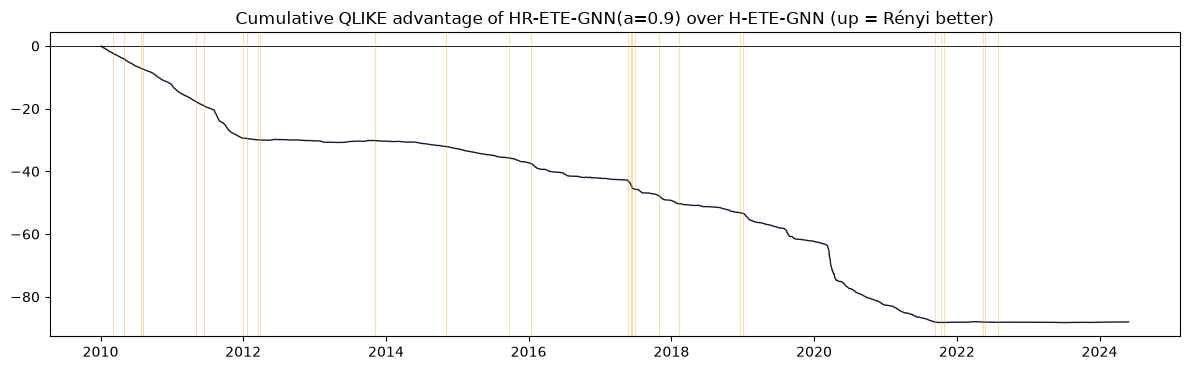

In [5]:
if not BASE_READY:
    print("Skipped: the Shannon baseline (run_alpha_1.0.ipynb) is not finished yet.")
else:
    res = ac.compare_to_shannon(ALPHA, base_runs, new_runs, data, cfg.tickers, SEEDS)
    print(f"test span {res['dates'][0].date()} -> {res['dates'][-1].date()}  ({len(res['dates'])} days)")
    display(res["headline"].round(5))
    display(res["per_etf"].round(4))
    s = res["summary"]
    print(f"{s['Model']} beats H-ETE-GNN on test QLIKE in {s['seeds_won']} of {s['n_seeds']} seeds")

    res["headline"].to_csv(TABLES / "test_headline.csv")
    res["per_etf"].to_csv(TABLES / "test_per_etf.csv", index=False)
    res["per_seed"].to_csv(TABLES / "test_per_seed.csv", index=False)

    ac.plot_cumulative(res, ALPHA, changes)
    plt.tight_layout(); plt.savefig(TABLES / "cumulative_qlike_advantage.png", dpi=150); plt.show()

## 4. Next

When all six α notebooks have finished, run `compare_all_alphas.ipynb`. It puts every α in one table and runs a Model Confidence Set over all of them.